<a href="https://colab.research.google.com/github/Suvetha72/Industry-Oriented-Marketing-Campaign-Performance-Analysis/blob/main/laptop_performance_predictor.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

            ModelName   CPUUsage   RAMUsage  Temperature    Voltage  \
0  Dell Inspiron 6880  48.447212  73.770260    59.971364  14.807143   
1   Dell ZenBook 2266  54.725241  25.221819    39.165106  15.727814   
2    Dell Galaxy 5903  26.693319  49.900628    93.052670  17.437338   
3   Dell ZenBook 8084  65.591652  29.603866    92.580189  10.645216   
4  Dell Inspiron 8884  24.395216  25.792754    76.175988  15.325681   

   DiskUsage  FanSpeed ProblemDetected  
0  15.502708      3507    Disk Failure  
1   4.421022      1037      No Problem  
2  25.180064      3244    Disk Failure  
3  57.713538      3731      No Problem  
4  83.788169      2830    Disk Failure  
Number of rows and columns:
(2000, 8)

Column names:
Index(['ModelName', 'CPUUsage', 'RAMUsage', 'Temperature', 'Voltage',
       'DiskUsage', 'FanSpeed', 'ProblemDetected'],
      dtype='object')

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 8 columns):
 #

,ModelName,CPUUsage,RAMUsage,Temperature,Voltage,DiskUsage,FanSpeed,ProblemDetected
0,Dell Inspiron 6880,48.447212,73.770260,59.971364,14.807143,15.502708,3507,Disk Failure
1,Dell ZenBook 2266,54.725241,25.221819,39.165106,15.727814,4.421022,1037,No Problem
2,Dell Galaxy 5903,26.693319,49.900628,93.052670,17.437338,25.180064,3244,Disk Failure
3,Dell ZenBook 8084,65.591652,29.603866,92.580189,10.645216,57.713538,3731,No Problem
4,Dell Inspiron 8884,24.395216,25.792754,76.175988,15.325681,83.788169,2830,Disk Failure


Last 5 rows:


,ModelName,CPUUsage,RAMUsage,Temperature,Voltage,DiskUsage,FanSpeed,ProblemDetected
1995,Toshiba MacBook 9232,41.378608,76.537004,47.828781,14.540910,75.902317,1717,Power Issue
1996,Toshiba Aspire 2699,74.572418,85.921111,29.751908,17.079307,96.925336,4674,Power Issue
1997,Toshiba Satellite 6631,7.647159,80.012268,70.180547,17.891195,69.970472,1312,Memory Leak
1998,Toshiba Vaio 7559,17.759062,96.870400,65.567972,17.258790,34.999741,2881,No Problem
1999,Toshiba Galaxy 7721,7.014647,64.768970,98.306343,11.503680,86.560713,3424,Overheating



Missing values:
ModelName          0
CPUUsage           0
RAMUsage           0
Temperature        0
Voltage            0
DiskUsage          0
FanSpeed           0
ProblemDetected    0
dtype: int64
Duplicate rows: 0

Column names:
['ModelName', 'CPUUsage', 'RAMUsage', 'Temperature', 'Voltage', 'DiskUsage', 'FanSpeed', 'ProblemDetected']

Problem detected distribution:
ProblemDetected
No Problem      413
Disk Failure    402
Power Issue     400
Overheating     395
Memory Leak     390
Name: count, dtype: int64

Performance status distribution:
Performance_Status
1    1587
0     413
Name: count, dtype: int64


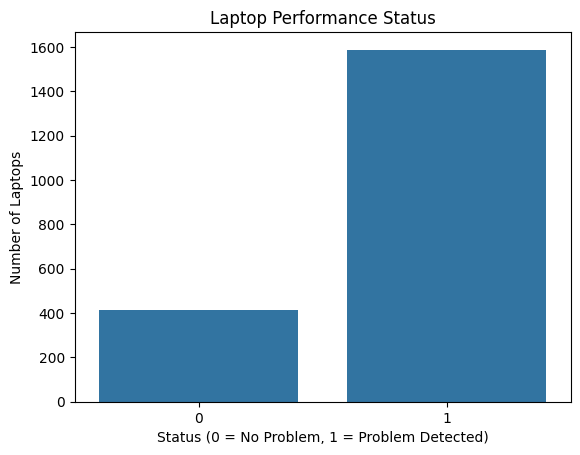

Input features:
    CPUUsage   RAMUsage  Temperature    Voltage  DiskUsage  FanSpeed
0  48.447212  73.770260    59.971364  14.807143  15.502708      3507
1  54.725241  25.221819    39.165106  15.727814   4.421022      1037
2  26.693319  49.900628    93.052670  17.437338  25.180064      3244
3  65.591652  29.603866    92.580189  10.645216  57.713538      3731
4  24.395216  25.792754    76.175988  15.325681  83.788169      2830

Target:
0    1
1    0
2    1
3    0
4    1
Name: Performance_Status, dtype: int64
Training data: (1600, 6)
Testing data: (400, 6)

Logistic Regression Accuracy: 0.5125
              precision    recall  f1-score   support

           0       0.24      0.64      0.35        83
           1       0.84      0.48      0.61       317

    accuracy                           0.51       400
   macro avg       0.54      0.56      0.48       400
weighted avg       0.71      0.51      0.56       400


Decision Tree Accuracy: 0.69
              precision    recall  f1-score 

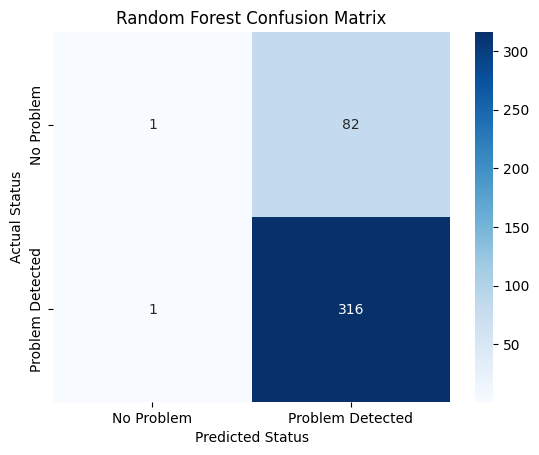


Enter New Laptop Details
Enter CPU Usage: 95
Enter RAM Usage: 92
Enter Temperature: 90
Enter Voltage: 1.3
Enter Disk Usage: 95
Enter Fan Speed: 5000

New Laptop Prediction Results
Logistic Regression: No Problem
Decision Tree: Problem Detected
Random Forest: Problem Detected

Best Algorithm: Random Forest
Best Model Accuracy: 0.7925


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

df = pd.read_csv("Laptop_Motherboard_Health_Monitoring_Dataset.csv")

print(df.head())

print("Number of rows and columns:")
print(df.shape)

print("\nColumn names:")
print(df.columns)

print("\nDataset information:")
df.info()

print("First 5 rows:")
display(df.head())

print("Last 5 rows:")
display(df.tail())

print("\nMissing values:")
print(df.isnull().sum())

print("Duplicate rows:", df.duplicated().sum())

print("\nColumn names:")
print(df.columns.tolist())

print("\nProblem detected distribution:")
print(df["ProblemDetected"].value_counts())

df["Performance_Status"] = df["ProblemDetected"].apply(
    lambda x: 0 if x == "No Problem" else 1
)

print("\nPerformance status distribution:")
print(df["Performance_Status"].value_counts())

sns.countplot(x="Performance_Status", data=df)

plt.title("Laptop Performance Status")
plt.xlabel("Status (0 = No Problem, 1 = Problem Detected)")
plt.ylabel("Number of Laptops")

plt.show()

features = [
    "CPUUsage",
    "RAMUsage",
    "Temperature",
    "Voltage",
    "DiskUsage",
    "FanSpeed"
]

X = df[features]
y = df["Performance_Status"]

print("Input features:")
print(X.head())

print("\nTarget:")
print(y.head())

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Logistic Regression

logistic_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

logistic_model.fit(X_train_scaled, y_train)

logistic_prediction = logistic_model.predict(X_test_scaled)

logistic_accuracy = accuracy_score(
    y_test,
    logistic_prediction
)

print("\nLogistic Regression Accuracy:", logistic_accuracy)

print(classification_report(
    y_test,
    logistic_prediction,
    zero_division=0
))

# Decision Tree

decision_tree = DecisionTreeClassifier(
    random_state=42,
    max_depth=5,
    class_weight="balanced"
)

decision_tree.fit(X_train, y_train)

tree_prediction = decision_tree.predict(X_test)

tree_accuracy = accuracy_score(
    y_test,
    tree_prediction
)

print("\nDecision Tree Accuracy:", tree_accuracy)

print(classification_report(
    y_test,
    tree_prediction,
    zero_division=0
))

# Random Forest

random_forest = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced"
)

random_forest.fit(X_train, y_train)

forest_prediction = random_forest.predict(X_test)

forest_accuracy = accuracy_score(
    y_test,
    forest_prediction
)

print("\nRandom Forest Accuracy:", forest_accuracy)

print(classification_report(
    y_test,
    forest_prediction,
    zero_division=0
))

# Compare Models

results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [
        logistic_accuracy,
        tree_accuracy,
        forest_accuracy
    ]
})

print("\nModel Comparison:")
print(results)


# Select the model with the best accuracy

best_model_name = results.loc[
    results["Accuracy"].idxmax(), "Model"
]

print("\nBest Algorithm:", best_model_name)

if best_model_name == "Logistic Regression":
    best_model = logistic_model

elif best_model_name == "Decision Tree":
    best_model = decision_tree

else:
    best_model = random_forest

print("Best Model Accuracy:",
      results.loc[results["Accuracy"].idxmax(), "Accuracy"])


# Confusion Matrix for Random Forest

cm = confusion_matrix(y_test, forest_prediction)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Problem", "Problem Detected"],
    yticklabels=["No Problem", "Problem Detected"]
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted Status")
plt.ylabel("Actual Status")

plt.show()

# New Laptop Prediction

print("\nEnter New Laptop Details")

cpu = float(input("Enter CPU Usage: "))
ram = float(input("Enter RAM Usage: "))
temperature = float(input("Enter Temperature: "))
voltage = float(input("Enter Voltage: "))
disk = float(input("Enter Disk Usage: "))
fan = float(input("Enter Fan Speed: "))

new_laptop = pd.DataFrame([[
    cpu,
    ram,
    temperature,
    voltage,
    disk,
    fan
]], columns=features)

# Predict using Logistic Regression

new_laptop_scaled = scaler.transform(new_laptop)

logistic_result = logistic_model.predict(new_laptop_scaled)[0]

# Predict using Decision Tree

tree_result = decision_tree.predict(new_laptop)[0]

# Predict using Random Forest

forest_result = random_forest.predict(new_laptop)[0]

print("\nNew Laptop Prediction Results")

print(
    "Logistic Regression:",
    "No Problem" if logistic_result == 0 else "Problem Detected"
)

print(
    "Decision Tree:",
    "No Problem" if tree_result == 0 else "Problem Detected"
)

print(
    "Random Forest:",
    "No Problem" if forest_result == 0 else "Problem Detected"
)


# Select the model with the best accuracy

best_model_name = results.loc[
    results["Accuracy"].idxmax(), "Model"
]

print("\nBest Algorithm:", best_model_name)

if best_model_name == "Logistic Regression":
    best_model = logistic_model

elif best_model_name == "Decision Tree":
    best_model = decision_tree

else:
    best_model = random_forest

print("Best Model Accuracy:",
      results.loc[results["Accuracy"].idxmax(), "Accuracy"])